# Recommender systems

Elke keer wanneer je een app als Netflix, Spotify of Youtube opent krijg je aanbevelingen van andere dingen die je misschien ook wel leuk zou vinden. Hoe werken deze algoritmes precies ? Worden deze getraind per individu, of zijn er andere systemen aan het werk ?

Recommender systemen geven voor elke gebruiker van een dienst een individuele lijst van voorgestelde items. Voor diensten zoals Netflix gaat dit over 100en miljoenen gebruikers, dus het is van belang om deze klanten efficiënt te kunnen leiden naar de producten die hen interesseren, anders zeggen ze hun abonnement op.

## Theorie

Wat we willen weten, is voor elke gebruiker (user) *u*, in welke mate die geïnteresseerd is (rating *r*) in een product *i*. We duiden in wat volgt die interesse aan met $r_{ui}$, de voorspelde rating van een user $u$ voor een product $i$. Zo is bijvoorbeeld de rating $$ r_{\textbf{Bruno}, \textbf{Mission Impossible 6}} $$ heel hoog als ik op Netflix alle vorige Mission Impossible films ook heb gezien.

Om de rangschikking te kunnen maken, heb je natuurlijk informatie nodig over de user, welke producten hij/zij leuk vindt. Er zijn 2 manier om aan deze informatie te raken:
- *Expliciete feedback*: indien de user via likes, reviews, aantal sterren, ... de kwaliteit van een aantal items aangeeft. Deze vorm van feedback is perfect, maar hebben we nooit voor alle producten
- *Impliciete feedback*: indien de user bepaalde producten al heeft bekeken, andere gelijkaardig films heeft gekeken, dan is dit een indicatie dat ik een andere film ook interessant zal vinden. Deze informatie hebben we veel meer dan de expliciete feedback, maar er zitten ook fouten in (bvb een film aangeklikt en beslist deze toch niet te kijken).

In [1]:
#TODO prentje invoegen

Een rating $r_{ui}$ gebaseerd op expliciete feedback zal dus, in de vorm van een matrix, er bijvoorbeeld als volgt uitzien:

\begin{array}{ccccc}
1 & 0 & 0 & 0 & 0 \\
0 & .4 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 \\
0 & 0.8 & 0 & 0.6 & 0 \\
0 & 0 & 0 & 0 & 0.8 \\
\end{array}


Deze matrix bevat typisch heel veel gaten. We noemen dit soort matrix een *ijle matrix* (Eng: *sparse matrix*).

Een matrix met impliciete informatie bevat enkel 0 of 1, en is ook ijl, maar bevat typisch wel meer entries:

\begin{array}{ccccc}
1 & 0 & 0 & 0 & 0 \\
0 & 1 & 1 & 1 & 0 \\
0 & 0 & 1 & 0 & 0 \\
1 & 1 & 1 & 1 & 0 \\
0 & 0 & 0 & 0 & 1 \\
\end{array}

Een rating $r_{ui}$ gebaseerd op impliciete feedback bevat typisch enkel 0 en 1 waardes: 1 indien de user geinterageerd heeft met een bepaald item, en 0 indien dit niet het geval is. Ook deze matrix is typisch ijl, al bevat hij meer data dan de matrix gebaseerd op expliciete feedback.

We noemen die matrix $r_{ui}$ in wat volgt de user-interactie matrix.

### Popular based, Content based, Collaborative filtering

Er zijn ook nog verschillende manieren om een recommender te bouwen:
- Popular based: simpelweg een globale top-tien, zoals de 'Meest bekeken in België' op Netflix. Dit is geen ML, maar simpelweg goed tellen in de database. Het is per definitie niet-gepersonaliseerd.
- Content based: indien je een bepaald item hebt bekeken, kan een algoritme je 'gelijkaardige' items voorstellen, gebaseerd op tags die aan dit item hangen, zoals genre. Dit werkt goed, maar is afhankelijk van wat vorige users goed vonden die deze film ook hebben gezien. Bovendien ziet elke kijker die dit item ziet, exact dezelfde suggesties
- Collaborative filtering: de aanbevelingen worden gemaakt op basis van de user-item interactie matrix. Dit is zelf nog eens opgesplitst in 2 onderverdelingen:
    - user-based collaborative filtering: we kijken naar een groep van gelijkaardige users, en daarvoor bepalen we voor elk item een gemiddelde ranking. Het hoogst gerankt item zal de user dan worden gepresenteerd als beste optie. Een belangrijk nadeel is dat we eerst iets over de user moeten weten, waarover later meer.
    - item-based collaborative filtering: je zoekt gelijkaardige items voor item(s) die de user leuk vindt. Het verschilt van content based in de manier waarop deze worden berekend: hier gebruiken we de user-item interactie matrix.
- Hybrid: een combinatie van bovenstaande

## Implementaties

### Popular based
Voor elk probleem hebben we een baseline nodig. We moeten dus minstens beter doen dan de simpelste optie, namelijk een top-N systeem.

#### Dataset inladen
Volgende code genereert data die we verder gaan gebruiken

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gc

from collections import defaultdict

# synthesize data
NUM_USERS = 10_000
NUM_ITEMS = 1_000
user_id = np.arange(start = 0, stop = NUM_USERS)
item_id = np.arange(start = 0, stop = NUM_ITEMS)
np.random.seed(42)

user_item_dict = defaultdict(list)
genres = ['Action','Comedy','Drama','Fantasy','Horror','Mystery','Romance','Thriller','Western']
for id in user_id:
    
    # random aantal items die we gaan raten
    # voor elke user tussen de 3 en de 5 items raten
    num_rand_item = np.random.randint(low = 3, high = 5)

    # kies random item_ids
    rand_items = np.random.choice(item_id, size = num_rand_item, replace = False)

    # kies random ratings
    rand_rating = np.random.randint(low = 1, high = 10, size = num_rand_item)

    # dictionary van  user-item parts.
    for uid, iid,rating in zip([id] * num_rand_item, rand_items, rand_rating):
        user_item_dict['user_id'].append(uid)
        user_item_dict['item_id'].append(iid)
        user_item_dict['rating'].append(rating)

# maak dataframe
ratings = pd.DataFrame(user_item_dict)
print("Rating Dataframe")
ratings[['user_id','item_id']] = ratings[['user_id','item_id']].astype(str)
display(ratings.head())

item_genre_dict = defaultdict(list)
for iid in item_id:

    # random aantal genres
    num_rand_genre = np.random.randint(low = 1, high = 3)
    # random kueze van genres
    rand_genres = np.random.choice(genres, size = num_rand_genre, replace = False)
    item_genre_dict['item_id'].append(iid)
    item_genre_dict['genres'].append(', '.join(list(rand_genres)))

# maak dataframe
items = pd.DataFrame(item_genre_dict)
print("\nItem Dataframe")
items = items.astype(str)
display(items.head())

Rating Dataframe


,user_id,item_id,rating
0,0,521,2
1,0,941,8
2,0,741,2
3,1,986,5
4,1,275,5



Item Dataframe


,item_id,genres
0,0,"Romance, Action"
1,1,Mystery
2,2,"Drama, Western"
3,3,"Fantasy, Horror"
4,4,"Comedy, Drama"


#### geavanceerde score:
We gebruiken deze formule om de globale rating van een film te bepalen.

WR = (v ÷ (v+m)) × R + (m ÷ (v+m)) × C

Hierbij is
- R = average rating van een film. (rating)
- v = aantal stemmen for the movie. (members)
- m = minimum aantal stemmen nodig om gelijst te worden in de top 250 ( > percentile 80 van alle stemmen)
- C = gemiddelde rating over heel de dataset tesamen

**Reference**

- [IMDB rating system](https://help.imdb.com/article/imdb/track-movies-tv/ratings-faq/G67Y87TFYYP6TWAV?ref_=helpms_helpart_inline#)

/tmp/ipykernel_1613/1219543735.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = pop_items.head(10),


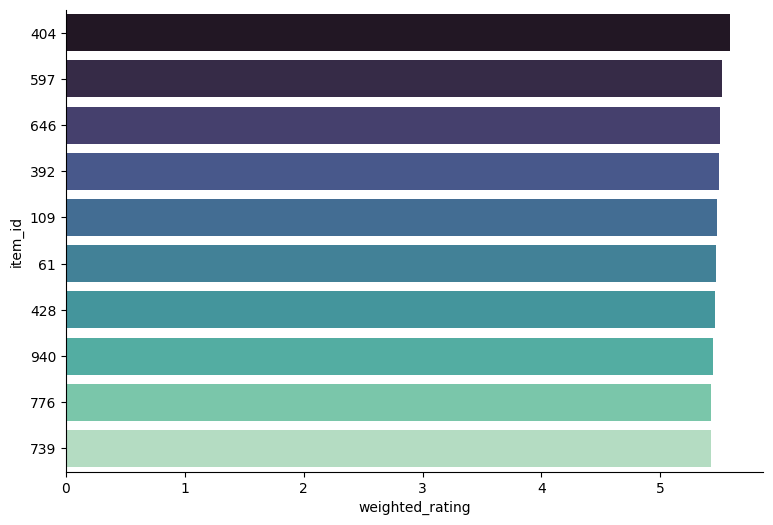

In [3]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

def weighted_rating(v,m,R,C): ## gegeven
    '''
    Calculate the weighted rating
    
    Args:
    v -> average rating for each item (float)
    m -> minimum votes required to be classified as popular (float)
    R -> average rating for the item (pd.Series)
    C -> average rating for the whole dataset (pd.Series)
    
    Returns:
    pd.Series
    '''
    return ( (v / (v + m)) * R) + ( (m / (v + m)) * C )

def assign_popular_based_score(rating_df, item_df, user_col, item_col, rating_col):
    '''
    Assigned popular based score based on the IMDB weighted average.
    
    Args:
    rating -> pd.DataFrame contains ['item_id', 'rating'] for each user.
    
    Returns
    popular_items -> pd.DataFrame contains item and IMDB weighted score.
    '''
    
    # pre processing
    vote_count = (
        rating_df
        .groupby(item_col,as_index=False)
        .agg( {user_col:'count', rating_col:'mean'} )
        )
    vote_count.columns = [item_col, 'vote_count', 'avg_rating']
    
    # bereken input parameters
    C = np.mean(vote_count['avg_rating'])
    m = np.percentile(vote_count['vote_count'], 70)
    vote_count = vote_count[vote_count['vote_count'] >= m]
    R = vote_count['avg_rating']
    v = vote_count['vote_count']
    vote_count['weighted_rating'] = weighted_rating(v,m,R,C)
    
    # post processing: dataframes terug samenvoegen
    vote_count = vote_count.merge(item_df, on = [item_col], how = 'left')
    popular_items = vote_count.loc[:,[item_col, 'genres', 'vote_count', 'avg_rating', 'weighted_rating']]
    
    return popular_items

# deze kolomnamen gaan we later nog gebruiken
USER_COL = 'user_id'
ITEM_COL = 'item_id'
RATING_COL = 'rating'

# berekening popularity based
pop_items = assign_popular_based_score(ratings, items, USER_COL, ITEM_COL, RATING_COL)
pop_items = pop_items.sort_values('weighted_rating', ascending = False)

# plot
fix, ax = plt.subplots(figsize=(9,6))
sns.barplot(data = pop_items.head(10),
            y = 'item_id',
            x = 'weighted_rating',
            palette = 'mako');
sns.despine(); #output onderdrukken

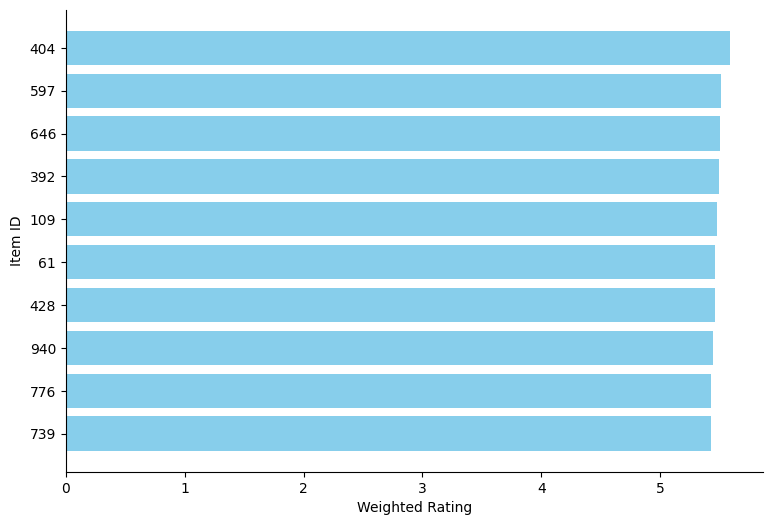

In [4]:
# Alternatieve code met seaborn
import matplotlib.pyplot as plt

# Your data (assuming 'pop_items' is your DataFrame)
pop_items_head = pop_items.head(10)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(pop_items_head['item_id'], pop_items_head['weighted_rating'], color='skyblue')

# Invert the y-axis to display the items in descending order
ax.invert_yaxis()

# Removing the top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Labeling the axes
ax.set_xlabel('Weighted Rating')
ax.set_ylabel('Item ID')

plt.show()


### Content based

Stel ik dat de film 'Mission Impossible V' erg goed vond. Dit algoritme gaat me aanbevelingen doen op basis van hetzelfde genre. 
In dit voorbeeld zit alle informatie over het gedrag van een user in een vector, met alle films die de user goed vond en de ratings ervan. Deze vector noemen we de *profile vector*: het bevat alle informatie van de user met betrekking tot de items in de dataset waarmee hij/wij heeft ingeïnterageerd.
We gaan de genres via een one-hot encoding toevoegen als numerieke features aan de dataset:

Het eerste wat we nodig hebben is de rated items, het bevat een lijst van de films met id en hun genres.

In [5]:
# preprocessing
rated_items = items.loc[items[ITEM_COL].isin(ratings[ITEM_COL])].copy()
rated_items.head(5)

,item_id,genres
0,0,"Romance, Action"
1,1,Mystery
2,2,"Drama, Western"
3,3,"Fantasy, Horror"
4,4,"Comedy, Drama"


Die genres zitten nog samen in 1 kolom, dus die gaan we uit elkaar trekken, en ook even checken dat we alle genres ergens opgeslagen hebben.

In [6]:
genre = rated_items['genres'].str.split(",", expand=True)
print(genre)

# get all possible genre
all_genre = set()
for c in genre.columns:
    distinct_genre = genre[c].str.lower().str.strip().unique()
    all_genre.update(distinct_genre)
all_genre.remove(None)

print(all_genre)

           0         1
0    Romance    Action
1    Mystery      None
2      Drama   Western
3    Fantasy    Horror
4     Comedy     Drama
..       ...       ...
995  Western      None
996   Comedy      None
997    Drama      None
998  Romance    Comedy
999  Fantasy      None

[1000 rows x 2 columns]
{'comedy', 'thriller', 'western', 'fantasy', 'drama', 'mystery', 'action', 'romance', 'horror'}


Nu beginnen we met het interessante werk. We hebben de user-item interactie matrix nodig. Die moeten we zelf in mekaar puzzelen:

In [7]:
item_genre_mat = rated_items[[ITEM_COL, 'genres']].copy()
print(item_genre_mat.head())
item_genre_mat['genres'] = item_genre_mat['genres'].str.lower().str.strip()

  item_id           genres
0       0  Romance, Action
1       1          Mystery
2       2   Drama, Western
3       3  Fantasy, Horror
4       4    Comedy, Drama


De genres zijn een cetagorische variabele. We gaan deze vervangen door een *one-hot encoding*: voor elk bestaand genre maken we een kolom, en we duiden in die kolom 1 aan, in alle andere 0. Dit is een typische strategie bij niet-numerieke variabelen vooraleer deze aan een algoritme mee te geven:

In [8]:
for genre in all_genre:
    item_genre_mat[genre] = np.where(item_genre_mat['genres'].str.contains(genre), 1, 0)
item_genre_mat = item_genre_mat.drop(['genres'], axis=1)
item_genre_mat = item_genre_mat.set_index(ITEM_COL)
print(item_genre_mat)

         comedy  thriller  western  fantasy  drama  mystery  action  romance  \
item_id                                                                        
0             0         0        0        0      0        0       1        1   
1             0         0        0        0      0        1       0        0   
2             0         0        1        0      1        0       0        0   
3             0         0        0        1      0        0       0        0   
4             1         0        0        0      1        0       0        0   
...         ...       ...      ...      ...    ...      ...     ...      ...   
995           0         0        1        0      0        0       0        0   
996           1         0        0        0      0        0       0        0   
997           0         0        0        0      1        0       0        0   
998           1         0        0        0      0        0       0        1   
999           0         0        0      

Dit is het soort matrix waarop we een similariteitsfunctie op kunnen loslaten. We willen in essentie weten welke films verwant zijn met welke films. We krijgen dan een vierkant matrix, die voor een entry op rij *i* en kolom *j* aangeeft hoe hard film *i* en film *j* op elkaar lijken. De diagonaal van deze matrix heeft overal 1, omdat daar elke film met zichzelf wordt vergeleken: perfect similariteit / gelijkaardigheid. Bovendien is deze matrix symmetrisch (film 1 en 5 vergelijken is hetzelfde als film 5 en 1 vergelijken).

In [9]:
from sklearn.metrics.pairwise import cosine_similarity

corr_mat = cosine_similarity(item_genre_mat)
print(corr_mat.shape)
print(corr_mat)

(1000, 1000)
[[1.         0.         0.         ... 0.         0.5        0.        ]
 [0.         1.         0.         ... 0.         0.         0.        ]
 [0.         0.         1.         ... 0.70710678 0.         0.        ]
 ...
 [0.         0.         0.70710678 ... 1.         0.         0.        ]
 [0.5        0.         0.         ... 0.         1.         0.        ]
 [0.         0.         0.         ... 0.         0.         1.        ]]


Nu hebben we een functie nodig die uit deze matrix de films haalt die het meest lijken op een bepaalde film. We gaan dus een functie maken met de volgende argumenten:
- item_id: naam van het te vergelijken item
- corr_mat: de similariteits of correlatiematrix die we net concreet hebben berekend
- to_k: aantal items dat we in volgorde willen teruggeven

We hebben ook een kleine hulpdictionary nodig die indexen omzet naar id's van items. In ons geval is de film al een id, maar dit kan in het algemeen lastig zijn. Ook de reverse lookup dictionary zal nuttig blijken.

In [10]:
ind2name = {ind:name for ind,name in enumerate(item_genre_mat.index)}
print(ind2name)
name2ind = {v:k for k,v in ind2name.items()} #omgekeerde index
print(name2ind)

{0: '0', 1: '1', 2: '2', 3: '3', 4: '4', 5: '5', 6: '6', 7: '7', 8: '8', 9: '9', 10: '10', 11: '11', 12: '12', 13: '13', 14: '14', 15: '15', 16: '16', 17: '17', 18: '18', 19: '19', 20: '20', 21: '21', 22: '22', 23: '23', 24: '24', 25: '25', 26: '26', 27: '27', 28: '28', 29: '29', 30: '30', 31: '31', 32: '32', 33: '33', 34: '34', 35: '35', 36: '36', 37: '37', 38: '38', 39: '39', 40: '40', 41: '41', 42: '42', 43: '43', 44: '44', 45: '45', 46: '46', 47: '47', 48: '48', 49: '49', 50: '50', 51: '51', 52: '52', 53: '53', 54: '54', 55: '55', 56: '56', 57: '57', 58: '58', 59: '59', 60: '60', 61: '61', 62: '62', 63: '63', 64: '64', 65: '65', 66: '66', 67: '67', 68: '68', 69: '69', 70: '70', 71: '71', 72: '72', 73: '73', 74: '74', 75: '75', 76: '76', 77: '77', 78: '78', 79: '79', 80: '80', 81: '81', 82: '82', 83: '83', 84: '84', 85: '85', 86: '86', 87: '87', 88: '88', 89: '89', 90: '90', 91: '91', 92: '92', 93: '93', 94: '94', 95: '95', 96: '96', 97: '97', 98: '98', 99: '99', 100: '100', 101: '1

Hoe dit uit de matrix vissen:
- een rij selecteren voor de film die we willen gebruiken om aanbevelingen van af te leiden
- hiervan op die rij alle kolommen sorteren van groot naar klein, en de grootste 10 kolommen meenemen
- terug de 'titels' van die kolommen teruggeven.

In [11]:
#TODO


Dit gieten we nu in een mooie functie:

In [12]:
def top_k_items(item_id, top_k, corr_mat, map_name):
    #TODO

_IncompleteInputError: incomplete input (392941205.py, line 2)

Die kunnen we dan gebruiken:

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
similar_items = top_k_items(name2ind['99'],
                            top_k = 10,
                            corr_mat = corr_mat,
                            map_name = ind2name)

# Print resultaat
print("De top-k films gelijkaardig aan item_id 99")
display(items.loc[items[ITEM_COL].isin(similar_items)])

#del corr_mat
gc.collect();

The top-k similar movie to item_id 99


,item_id,genres
0,0,"Romance, Action"
99,99,"Romance, Action"
211,211,"Romance, Action"
352,352,"Romance, Action"
512,512,"Action, Romance"
618,618,"Romance, Action"
737,737,"Action, Romance"
744,744,"Romance, Action"
813,813,"Action, Romance"
858,858,"Romance, Action"


### Collaborative filtering

Zelfs hier zijn er nog onderverdelingen.

#### Memory-based

Wat we nu willen doen is de 'similarity', of gelijkaardigheid tussen personen of items onderling bepalen. Hiervoor hebben we een *similarity metric* nodig. Er zijn verschillende keuzes:
- Pearson correlation: correlatie heb je al eens gezien in Mathematical Foundations (?)
- Cosine similarity: dit berekent in een multi-dimensionale ruimte de hoek tussen 2 datapunten. Als ze dezelfde 'richting' hebben, kan dat worden geïnterpreteerd als 'dezelfde soort dingen interessant vinden" in dit probleem.
- Andere zoals Time-Decay Latent Dirichlet Allocation (misschien in de oefeningen). 

**Gebruikersgebaseerde implementatie**

- We vinden de groep vergelijkbare gebruikers (de groepsgrootte is willekeurig) op basis van de keuze van metriek. 
 - We berekenen het gemiddelde van de beoordeling van elk item op basis van de groep vergelijkbare gebruikers 
- Rangschik het item op basis van de aflopende gemiddelde beoordeling en beveel de doelgebruiker aan met het item waarmee ze nog nooit eerder interactie hebben gehad. 

We hebben een nieuwe module nodig, van scipy: de sparse library om te rekenen met ijle matrices.

In [ ]:
from scipy.sparse import csr_matrix

We gaan de user-item matrix opstellen:

In [ ]:
# preprocess data
row = ratings[USER_COL]
col = ratings[ITEM_COL]
data = ratings[RATING_COL]

# init user-item matrix
mat = csr_matrix((data, (row, col)), shape=(NUM_USERS, NUM_ITEMS))
mat.eliminate_zeros()
print(mat) #enkel de niet nulle items worden aangeduid ! dit is veel efficienter dan de hele matrix bijhouden in het gevalk van ijle matrices.

  (0, 521)	2
  (0, 741)	2
  (0, 941)	8
  (1, 93)	1
  (1, 275)	5
  (1, 909)	1
  (1, 986)	5
  (2, 298)	5
  (2, 513)	7
  (2, 799)	8
  (2, 859)	5
  (3, 345)	3
  (3, 592)	9
  (3, 941)	2
  (4, 228)	8
  (4, 280)	5
  (4, 741)	2
  (5, 54)	4
  (5, 628)	6
  (5, 981)	9
  (6, 144)	2
  (6, 445)	7
  (6, 635)	4
  (7, 82)	6
  (7, 141)	4
  :	:
  (9992, 472)	2
  (9992, 641)	1
  (9993, 413)	5
  (9993, 835)	9
  (9993, 936)	3
  (9994, 205)	2
  (9994, 440)	4
  (9994, 805)	4
  (9995, 472)	2
  (9995, 850)	3
  (9995, 882)	8
  (9996, 318)	4
  (9996, 841)	1
  (9996, 934)	3
  (9996, 945)	9
  (9997, 27)	9
  (9997, 122)	3
  (9997, 728)	7
  (9998, 201)	8
  (9998, 415)	4
  (9998, 529)	6
  (9999, 64)	1
  (9999, 367)	2
  (9999, 422)	7
  (9999, 656)	3


We gaan even aanduiden hoe ijl deze matrix nu eigenlijk is:

In [ ]:
# calculate sparsity
sparsity = float(len(mat.nonzero()[0]))
sparsity /= (mat.shape[0] * mat.shape[1])
sparsity *= 100
print(f'Sparsity: {sparsity:4.2f}%. Dus {sparsity:4.2f}% van de user-item matrix is ingevuld.')

Sparsity: 0.35%. Dus 0.35% van de user-item matrix is ingevuld.


Nu gaan we opnieuw de cosine-similarity gebruiken, maar deze keer staan de items als kolom, niet als rij... Hiervoor moeten we de matrix transformeren:

In [ ]:
mat.shape

(10000, 1000)

In [ ]:
item_corr_mat = cosine_similarity(mat.T)

In [ ]:
item_corr_mat.shape

(1000, 1000)

In [ ]:
# get top k item
print("\nThe top-k similar movie to item_id 99")
similar_items = top_k_items(name2ind['99'],
                            top_k = 10,
                            corr_mat = item_corr_mat,
                            map_name = ind2name)

display(items.loc[items[ITEM_COL].isin(similar_items)])


The top-k similar movie to item_id 99


,item_id,genres
99,99,"Romance, Action"
248,248,Horror
352,352,"Romance, Action"
392,392,"Romance, Action"
507,507,"Horror, Western"
570,570,Horror
730,730,Fantasy
757,757,"Romance, Thriller"
824,824,Fantasy
899,899,Comedy


Dit resultaat is verschillend van content-based. De similarity is gebaseerd eerder op de users, want dat waren nu precies de kolommen, en niet meer op de genres, want dat waren de attributen bij content-based.

**Implementatie op basis van items**

- We vinden de groep vergelijkbare objecten op basis van de gekozen metriek. Selecteer tot de top-k meest vergelijkbare items om aan te bevelen.

**Probleem**

Het probleem met de memory based methode is dat je voor elke nieuwe gebruiker de similarity index moet berekenen, wat al snel heel tijdsintensief kan worden, of gewoon onmogelijk omdat de matrices te ijl worden. We kunnen niet blijven werken met de hele matrix, die wordt simpelweg te groot om in het geheugen te houden, en moet bovendien elke keer worden aangepast.

#### Model-based

Tot slot model-based collaborative filtering. Dit gebruikt (eindelijk!) ML algoritmes om de users rating te voorspellen. Meestal zijn deze algoritmes gebaseerd op een soort van *matrix factorisatie*: dat is een techniek om een matrix op te splitsen in verschillende simpelere matrices, waardoor je een inzicht krijgt in de belangrijkste dominante structuren in die matrix. Er zijn verschillende implementaties beschikbaar (de algoritmes zelf steunen op wiskundige technieken die nogal ver leiden)

**Truncated SVD**

SVD staat voor [Singular Value Decomposition](https://en.wikipedia.org/wiki/Singular_value_decomposition). Het breekt een matrix op in 3 factoren, waarin de middenste matrix een diagonale matrix is. Door in deze matrix een deel van de informatie weg te gooien (*truncate*) krijg je een kleiner object. Dit is eigenlijk exact equivalent met PCA, wat we in de les over dimensie reductie hebben behandeld.

In [ ]:
from sklearn.decomposition import TruncatedSVD

epsilon = 1e-9 #deze gaan we toevoegen omdat er numerieke instabliteit kan optreden bij SVD, en te vermijden dat er geen nul data is
n_latent_factors = 10 # aantal dimensies / items die je wil overhouden

# calculate item latent matrix
item_svd = TruncatedSVD(n_components = n_latent_factors) #initialisatie object, dit is een dimensie reductie techniek
item_features = item_svd.fit_transform(mat.transpose() + epsilon)
item_features.shape #voor elke item zijn er nu componenten opgesteld

(1000, 10)

We stellen voor de user een gelijkaardige matrix op, nu gaan we de matrix natuurlijk niet transponeren:

In [ ]:
# calculate user latent matrix
user_svd = TruncatedSVD(n_components = n_latent_factors)
user_features = user_svd.fit_transform(mat) + epsilon
user_features.shape

(10000, 10)

In [ ]:
# compute similarity
item_corr_mat = cosine_similarity(item_features)

# get top k item
print("\nThe top-k similar movie to item_id 99")
similar_items = top_k_items(name2ind['99'],
                            top_k = 10,
                            corr_mat = item_corr_mat,
                            map_name = ind2name)

display(items.loc[items[ITEM_COL].isin(similar_items)])


The top-k similar movie to item_id 99


,item_id,genres
4,4,"Comedy, Drama"
51,51,"Fantasy, Drama"
99,99,"Romance, Action"
219,219,Romance
239,239,"Comedy, Fantasy"
392,392,"Romance, Action"
619,619,"Romance, Western"
739,739,"Fantasy, Mystery"
755,755,"Thriller, Action"
881,881,"Western, Action"


Nu zou de aanbeveling gebaseerd zijn op enkele latente factoren die we niet direct kunnen verklaren. Maar wiskundig gezien zal het de hoogste latente factor zijn die het verlies tussen de werkelijke beoordeling en de gereconstrueerde beoordeling minimaliseert. Je kunt zien dat we nu de grootte van de matrix verkleinen in vergelijking met die in de op geheugen gebaseerde benadering, precies door de truncaded SVD te hanteren. Het is echter nog steeds niet goed genoeg, want uiteindelijk wanneer de gebruiker, of itemgrootte groeit met de tijd, zal het ook de beperking van de rekenkracht bereiken.

**Funk MF - voor de oefeningen**
Als laatste implementeren we met de library Funk MF - tijdens de oefeningen

Conda omgeving updaten: `conda install -c conda-forge scikit-surprise`